# Чекпойнт №2 · Разведочный анализ данных
**Модель 3. Robotic perception: локализация незнакомых предметов в складском контейнере**  
Максимилиан Казаков · Research-трек, компьютерное зрение

**Вопрос исследования.** Можно ли локализовать предметы, которых не было в обучающем наборе, и какие свойства складской сцены усложняют эту задачу? Единица съёмки — одна укладка предметов в контейнере (сцена); единица разметки — видимый экземпляр в кадре. Из его пиксельной маски получаем прямоугольник для 2D-детекции.

| Кандидат | Что даёт для задачи | Ограничение |
| :-- | :-- | :-- |
| **[WISDOM-Real (UC Berkeley)](https://sites.google.com/view/wisdom-dataset/dataset_links)** | Реальные RGB-D кадры контейнера, маски видимых экземпляров, авторское разделение физических предметов между train и test. | В публичных масках нет категорий и постоянных SKU. |
| [ARC2017 RGB-D (MPRG)](https://mprg.jp/research/arc_dataset_2017_e) | Складские контейнеры, bounding boxes и отдельные наборы для известных и неизвестных предметов. | При выборе архив на сервере автора не удалось получить. |
| [RU-APC в формате BOP](https://bop.felk.cvut.cz/datasets/#RU-APC) | Реальные кадры складской полки и метки идентичности целевого товара. | В поднаборе BOP19 размечен один целевой предмет на кадр, чего недостаточно для анализа всех предметов в сцене. |

**Выбор: WISDOM-Real.** Используем компактный архив и оба сенсора. Авторы использовали 25 физических предметов для обучения и 25 других для тестирования. Поэтому в этом ноутбуке **ID** — экземпляры из авторского `train`, **новые** — из авторского `test`. Это статус по разбиению, а не класс товара. Число появлений конкретного SKU, семантические ошибки классификации и разделение знакомых и незнакомых предметов внутри одной сцены на этой разметке оценить нельзя. Фон не считается классом предмета.

**Источники:** [страница данных и условия использования](https://sites.google.com/view/wisdom-dataset/dataset_links), [статья Danielczuk и др.](https://arxiv.org/abs/1809.05825), [код и формат масок авторов](https://github.com/BerkeleyAutomation/sd-maskrcnn). Изображения и аннотации: UC Berkeley, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); на иллюстрации поверх оригиналов нанесены рамки или преобразования, указанные в подписях.

## 1. Загрузка и проверка файлов

Путь и команды скачивания описаны в [README](README.md). Код принимает оригинальные файлы из архива; он ничего в них не меняет. `modal_segmasks` — видимые маски с локальными ID: 0 означает фон, разные положительные числа — разные экземпляры. `segmasks_filled` проверяем как отдельную бинарную аннотацию, но рамки из неё не строим. В компактной версии глубина представлена обработанным PNG; анализируем уровни интенсивности, без перевода в миллиметры и без вывода об исходных пропусках датчика.

In [1]:
from pathlib import Path
import hashlib
import os

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

cv2.setNumThreads(2)
sns.set_theme(style="whitegrid", palette=["#176B87", "#D26042"])
plt.rcParams.update({"figure.dpi": 105, "axes.titleweight": "bold"})
pd.options.display.max_columns = 25

possible_roots = [
    Path(os.environ.get("WISDOM_ROOT", "data/wisdom-real")),
    Path("model_3/data/wisdom-real"),
]
ROOT = next((p for p in possible_roots if (p / "high-res").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Распакуйте WISDOM-Real по инструкции из README или задайте WISDOM_ROOT.")

CAMERAS = {"high-res": (772, 1032), "low-res": (480, 640)}  # H, W
MODALITIES = ("color_ims", "depth_ims", "modal_segmasks", "segmasks_filled")
SPLIT_NAMES = {"train": "ID · train", "test": "Новые · test"}

def image_path(camera, modality, frame_id):
    return ROOT / camera / modality / f"image_{frame_id:06d}.png"

def read_png(camera, modality, frame_id):
    path = image_path(camera, modality, frame_id)
    return cv2.imread(str(path), cv2.IMREAD_UNCHANGED) if path.is_file() else None

splits, file_ids = {}, {}
inventory = []
for camera in CAMERAS:
    for split in ("train", "test"):
        raw = np.load(ROOT / camera / f"{split}_indices.npy", allow_pickle=False)
        assert raw.ndim == 1 and raw.dtype.kind in "iu" and len(set(raw)) == len(raw)
        splits[camera, split] = set(map(int, raw))
    assert not (splits[camera, "train"] & splits[camera, "test"])
    expected = splits[camera, "train"] | splits[camera, "test"]
    for modality in MODALITIES:
        file_ids[camera, modality] = {
            int(path.stem.removeprefix("image_"))
            for path in (ROOT / camera / modality).glob("image_*.png")
        }
        found = file_ids[camera, modality]
        inventory.append({
            "Камера": camera, "Модальность": modality, "Файлов": len(found),
            "Пропуски": len(expected - found), "Доля пропусков, %": 100 * len(expected - found) / len(expected),
            "Вне индексов": len(found - expected),
        })

display(pd.DataFrame(inventory))
for split in ("train", "test"):
    assert splits["high-res", split] == splits["low-res", split]
print("У обоих сенсоров совпадает разбиение по ID сцен.")

,Камера,Модальность,Файлов,Пропуски,"Доля пропусков, %",Вне индексов
0,high-res,color_ims,400,0,0.0,0
1,high-res,depth_ims,400,0,0.0,0
2,high-res,modal_segmasks,400,0,0.0,0
3,high-res,segmasks_filled,400,0,0.0,0
4,low-res,color_ims,400,0,0.0,0
5,low-res,depth_ims,400,0,0.0,0
6,low-res,modal_segmasks,400,0,0.0,0
7,low-res,segmasks_filled,400,0,0.0,0


У обоих сенсоров совпадает разбиение по ID сцен.


In [2]:
image_rows, object_rows, issue_rows = [], [], []
for (camera, split), scene_ids in splits.items():
    for frame_id in sorted(scene_ids):
        h, w = CAMERAS[camera]
        color, depth, mask, filled = [read_png(camera, modality, frame_id) for modality in MODALITIES]
        issues = []
        for modality, im in zip(MODALITIES, (color, depth, mask, filled)):
            if im is None:
                issues.append(f"{modality}: отсутствует или не декодируется")
            elif im.dtype != np.uint8 or im.shape != ((h, w, 3) if modality in MODALITIES[:2] else (h, w)):
                issues.append(f"{modality}: неожиданный тип или форма")
        row = dict(camera=camera, split=split, frame_id=frame_id, ok=not issues, width=w, height=h)
        if issues:
            issue_rows.extend((camera, frame_id, issue) for issue in issues)
            image_rows.append(row)
            continue

        counts = np.bincount(mask.ravel(), minlength=256)
        ids = np.flatnonzero(counts[1:]) + 1
        gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
        depth_gray = depth[:, :, 0]
        if not (np.array_equal(depth_gray, depth[:, :, 1]) and np.array_equal(depth_gray, depth[:, :, 2])):
            issues.append("depth: не совпадают каналы")
        if not np.isin(np.unique(filled), [0, 255]).all():
            issues.append("filled: не бинарная аннотация")
        if len(ids) and counts[0] == 0:
            issues.append("modal: нет фоновых пикселей")
        row.update(
            ok=not issues, n_objects=len(ids),
            mask_coverage=100 * (mask.size - counts[0]) / mask.size,
            rgb_mean=float(gray.mean()), rgb_contrast=float(gray.std()),
            sharpness=float(cv2.Laplacian(gray, cv2.CV_32F).var()),
            depth_mean=float(depth_gray.mean()),
            depth_zero_pct=100 * (depth_gray == 0).mean(),
            nonconsecutive_ids=bool(len(ids) and ids[-1] != len(ids)),
            rgb_sha256=hashlib.sha256(color.tobytes()).hexdigest(),
        )
        image_rows.append(row)
        issue_rows.extend((camera, frame_id, issue) for issue in issues)
        if issues:
            continue

        for instance_id in ids:
            x0, y0, bw, bh = cv2.boundingRect(np.uint8(mask == instance_id))
            n_pixels = int(counts[instance_id])
            object_rows.append(dict(
                camera=camera, split=split, frame_id=frame_id, instance_id=int(instance_id),
                x0=x0, y0=y0, x1=x0 + bw, y1=y0 + bh, mask_px=n_pixels,
                bbox_w=bw, bbox_h=bh, min_side=min(bw, bh),
                mask_pct=100 * n_pixels / (w * h), bbox_pct=100 * bw * bh / (w * h),
                bbox_fill=100 * n_pixels / (bw * bh), bbox_ratio=bw / bh, n_objects=len(ids),
            ))

images = pd.DataFrame(image_rows)
boxes = pd.DataFrame(object_rows)
quality_issues = pd.DataFrame(issue_rows, columns=["camera", "frame_id", "issue"])
valid = images.loc[images.ok].copy()

shape_ok = (
    boxes.x0.ge(0) & boxes.y0.ge(0) & boxes.bbox_w.gt(0) & boxes.bbox_h.gt(0)
    & boxes.x1.le(boxes.camera.map({k: v[1] for k, v in CAMERAS.items()}))
    & boxes.y1.le(boxes.camera.map({k: v[0] for k, v in CAMERAS.items()}))
    & boxes.bbox_fill.between(0, 100, inclusive="right")
)
assert shape_ok.all(), "Проверьте расчёт прямоугольников."
duplicates = valid[valid.duplicated("rgb_sha256", keep=False)]
cross_split = valid.groupby("rgb_sha256")["split"].nunique().gt(1).sum()
checks = pd.Series({
    "Кадры, запланированные к проверке": len(images),
    "Кадры с валидными RGB, depth и аннотациями": int(images.ok.sum()),
    "Кадры с зарегистрированной ошибкой качества": int((~images.ok).sum()),
    "Кадры с пустой modal-маской": int(valid.n_objects.eq(0).sum()),
    "Кадры с непоследовательными ID экземпляров": int(valid.nonconsecutive_ids.sum()),
    "Кадры, участвующие в точных дубликатах RGB": len(duplicates),
    "Совпавшие RGB-хэши между train и test": int(cross_split),
    "Кадры с нулём в обработанном depth PNG": int(valid.depth_zero_pct.gt(0).sum()),
    "Недопустимые рамки": int((~shape_ok).sum()),
}, name="Количество")
display(checks.to_frame())
if not quality_issues.empty:
    display(quality_issues)

,Количество
"Кадры, запланированные к проверке",800
"Кадры с валидными RGB, depth и аннотациями",800
Кадры с зарегистрированной ошибкой качества,0
Кадры с пустой modal-маской,0
Кадры с непоследовательными ID экземпляров,1
"Кадры, участвующие в точных дубликатах RGB",0
Совпавшие RGB-хэши между train и test,0
Кадры с нулём в обработанном depth PNG,0
Недопустимые рамки,0


**Правила обработки.** Кадр с отсутствующим, битым или структурно несовместимым файлом попадает в журнал и исключается из сводок по валидным кадрам. Пропущенный номер локального ID не означает пропуск разметки: считаем уникальные положительные значения, а не максимальный ID. Пустая маска, если встретится, обозначается отдельно, поскольку в общем случае возможна сцена без видимых экземпляров. Совпадение хэшей ищет только точные копии декодированного RGB; отсутствие таких копий не гарантирует отсутствия похожих укладок. Парные кадры одной сцены нельзя разносить между частями выборки.

## 2. Состав, баланс и геометрия объектов

Отдельно считаем сцены, кадры и видимые аннотации. Если один объект виден на обеих камерах, в таблице экземпляров он учитывается дважды. Метка видимости не содержит полного контура перекрытого предмета, поэтому малая площадь может означать и маленький предмет, и сильное перекрытие.

In [3]:
summary = (
    valid.groupby(["camera", "split"]).agg(
        Кадры=("frame_id", "size"), Сцены=("frame_id", "nunique"), Аннотации=("n_objects", "sum"),
        Медиана_предметов=("n_objects", "median"), Максимум_предметов=("n_objects", "max"),
        Медиана_покрытия_проц=("mask_coverage", "median"),
    )
)
display(summary.round(2))
display(valid.groupby("split").agg(Сцены=("frame_id", "nunique"), Кадры=("frame_id", "size"),
                                  Аннотации=("n_objects", "sum")))
described = ["mask_pct", "bbox_pct", "bbox_fill", "bbox_ratio", "min_side"]
display(boxes.groupby(["camera", "split"])[described].quantile([.05, .50, .95]).round(2))

paired = valid.pivot(index=["split", "frame_id"], columns="camera", values="n_objects").dropna()
paired["delta"] = paired["high-res"] - paired["low-res"]
print(f"Полных пар: {len(paired)}; число видимых аннотаций различается в {paired.delta.ne(0).sum()} парах.")

Кадры  Сцены  Аннотации  Медиана_предметов  \
camera   split                                               
high-res test     300    300       1434                4.0   
         train    100    100        491                5.0   
low-res  test     300    300       1430                4.0   
         train    100    100        494                5.0   

                Максимум_предметов  Медиана_покрытия_проц  
camera   split                                             
high-res test                   12                   7.83  
         train                  11                   6.41  
low-res  test                   11                   4.65  
         train                  12                   3.77

,Сцены,Кадры,Аннотации
split,,,
test,300,600,2864
train,100,200,985


mask_pct  bbox_pct  bbox_fill  bbox_ratio  min_side
camera   split                                                          
high-res test  0.05      0.35      0.50      31.80        0.50     53.65
               0.50      1.39      2.46      60.34        1.19    112.00
               0.95      4.56      7.06      89.24        2.62    206.35
         train 0.05      0.49      0.72      29.71        0.51     51.50
               0.50      1.16      1.77      65.64        1.15    100.00
               0.95      2.82      7.72      87.30        3.69    221.00
low-res  test  0.05      0.21      0.29      34.39        0.50     26.00
               0.50      0.84      1.47      62.23        1.19     54.00
               0.95      2.59      4.14      89.03        2.61     98.00
         train 0.05      0.29      0.42      28.58        0.52     25.00
               0.50      0.67      1.03      66.84        1.19     48.00
               0.95      1.63      4.24      87.24        3.69     99.00

Полных пар: 400; число видимых аннотаций различается в 22 парах.


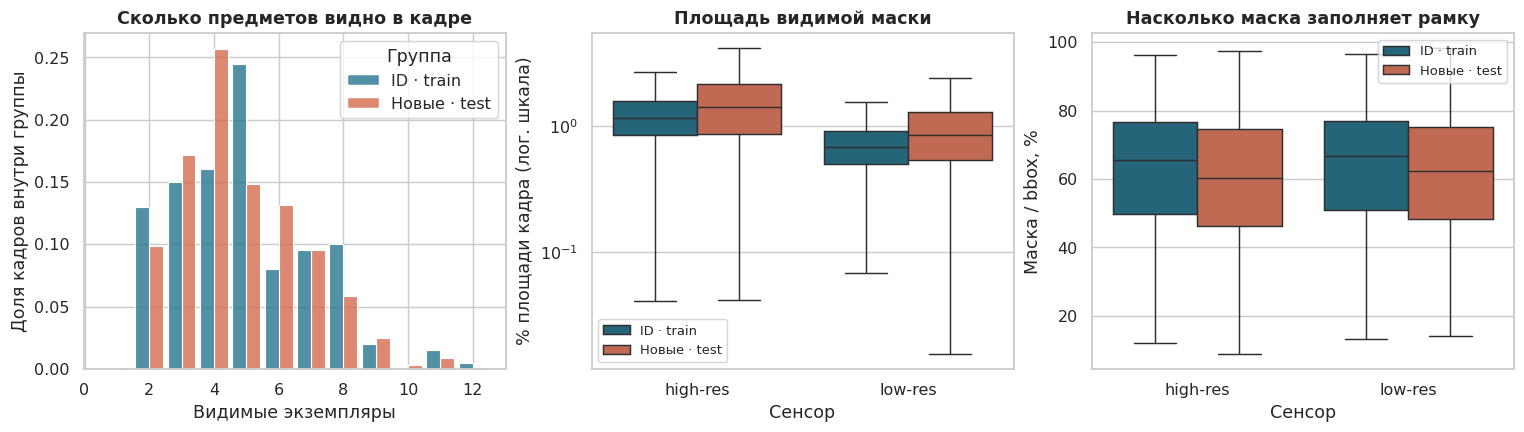

In [4]:
plot_frames = valid.assign(Группа=valid.split.map(SPLIT_NAMES))
plot_boxes = boxes.assign(Группа=boxes.split.map(SPLIT_NAMES))
fig, axs = plt.subplots(1, 3, figsize=(14.4, 4), layout="constrained")
n_lo, n_hi = int(valid.n_objects.min()), int(valid.n_objects.max())
sns.histplot(data=plot_frames, x="n_objects", hue="Группа", stat="probability",
             common_norm=False, bins=np.arange(n_lo-.5, n_hi+1.5), discrete=True,
             multiple="dodge", shrink=.86, ax=axs[0])
axs[0].set(title="Сколько предметов видно в кадре", xlabel="Видимые экземпляры", ylabel="Доля кадров внутри группы")
sns.boxplot(data=plot_boxes, x="camera", y="mask_pct", hue="Группа", showfliers=False, ax=axs[1])
axs[1].set(yscale="log", title="Площадь видимой маски", xlabel="Сенсор", ylabel="% площади кадра (лог. шкала)")
sns.boxplot(data=plot_boxes, x="camera", y="bbox_fill", hue="Группа", showfliers=False, ax=axs[2])
axs[2].set(title="Насколько маска заполняет рамку", xlabel="Сенсор", ylabel="Маска / bbox, %")
for ax in axs[1:]:
    ax.legend(title=None, fontsize=9)
plt.show()

Диаграмма числа предметов нормирована внутри группы; в неё входят кадры обеих камер, поэтому она описательная. Коробчатые диаграммы скрывают крайние точки только для читаемости, без удаления строк из анализа. Отношение площади маски к рамке характеризует геометрию видимой области, но **не является** измерением доли перекрытия: на него влияет и форма предмета.

## 3. Связи признаков и риск спутать новизну со свойствами съёмки

Сравним геометрию экземпляров и характеристики кадров. Корреляции Спирмена считаем **отдельно по камерам**, чтобы не смешивать разрешения. У бинарного статуса «новый» нет объектной разметки внутри кадра, поэтому связи со статусом считаем на уровне кадров. Они нужны, чтобы найти возможные побочные признаки, а не обосновать правило классификации. Средняя яркость, контраст и резкость рассчитаны по всему RGB-кадру; метрика резкости также реагирует на текстуру и края, поэтому малые значения — повод посмотреть кадр, а не автоматически удалить его.

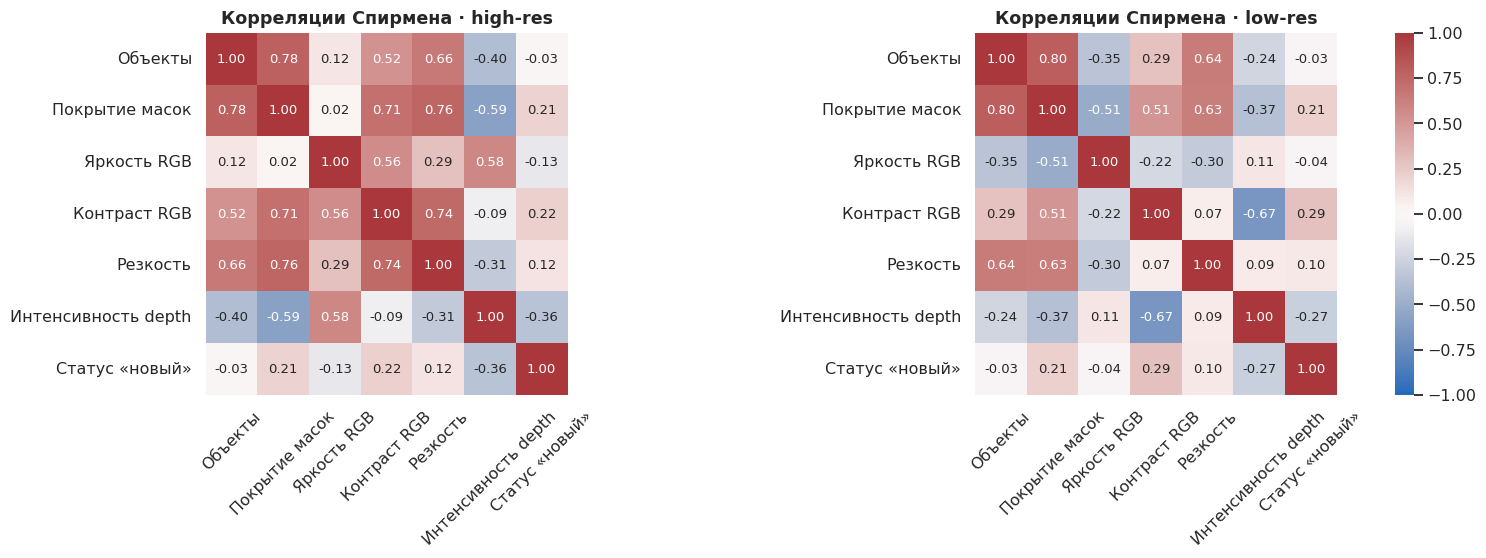

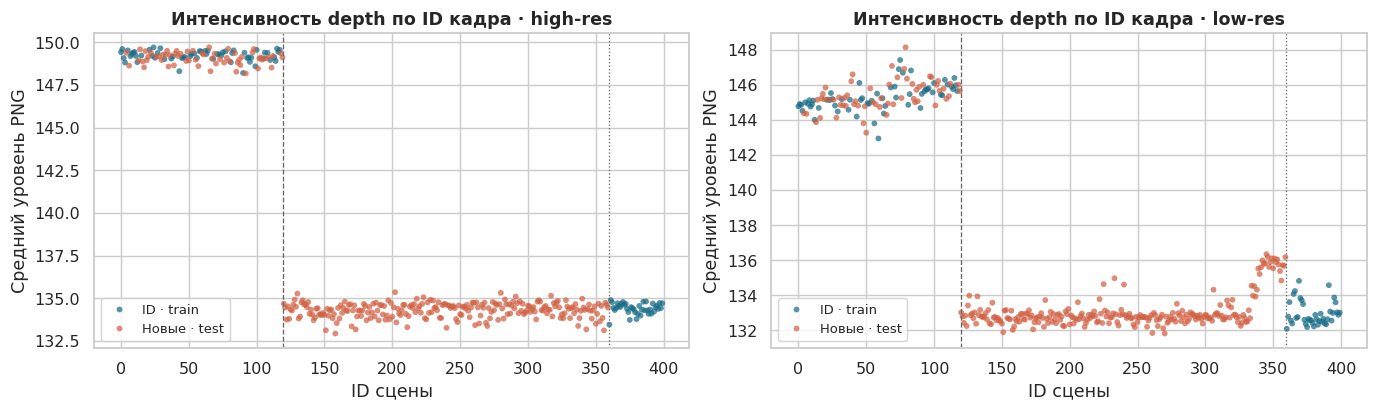

Кадры  Медиана_depth
camera   Интервал_ID split                      
high-res 0–119       test      60         149.12
                     train     60         149.27
         120–359     test     240         134.39
         360–399     train     40         134.43
low-res  0–119       test      60         145.24
                     train     60         145.19
         120–359     test     240         132.80
         360–399     train     40         132.69

In [5]:
frame_features = {
    "n_objects": "Объекты", "mask_coverage": "Покрытие масок",
    "rgb_mean": "Яркость RGB", "rgb_contrast": "Контраст RGB",
    "sharpness": "Резкость", "depth_mean": "Интенсивность depth",
    "is_novel": "Статус «новый»",
}
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained")
for i, (ax, camera) in enumerate(zip(axs, CAMERAS)):
    local = valid.loc[valid.camera.eq(camera)].assign(is_novel=lambda d: d.split.eq("test").astype(int))
    corr = local[list(frame_features)].rename(columns=frame_features).corr(method="spearman")
    sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f",
                square=True, cbar=(i == 1), ax=ax, annot_kws={"fontsize": 9})
    ax.set(title=f"Корреляции Спирмена · {camera}")
    ax.tick_params(axis="x", labelrotation=45)
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
for ax, camera in zip(axs, CAMERAS):
    local = plot_frames[plot_frames.camera.eq(camera)]
    sns.scatterplot(data=local, x="frame_id", y="depth_mean", hue="Группа",
                    s=16, alpha=.72, linewidth=0, ax=ax)
    ax.set(title=f"Интенсивность depth по ID кадра · {camera}", xlabel="ID сцены",
           ylabel="Средний уровень PNG")
    ax.legend(title=None, fontsize=9)
    ax.axvline(119.5, color="0.40", ls="--", lw=.9)
    ax.axvline(359.5, color="0.40", ls=":", lw=.9)
plt.show()

# Интервалы описывают структуру релиза, для настройки детектора они не используются.
batches = valid.assign(
    Интервал_ID=pd.cut(valid.frame_id, [-1, 119, 359, 399], labels=["0–119", "120–359", "360–399"])
)
display(batches.groupby(["camera", "Интервал_ID", "split"], observed=True)
        .agg(Кадры=("frame_id", "size"), Медиана_depth=("depth_mean", "median")).round(2))

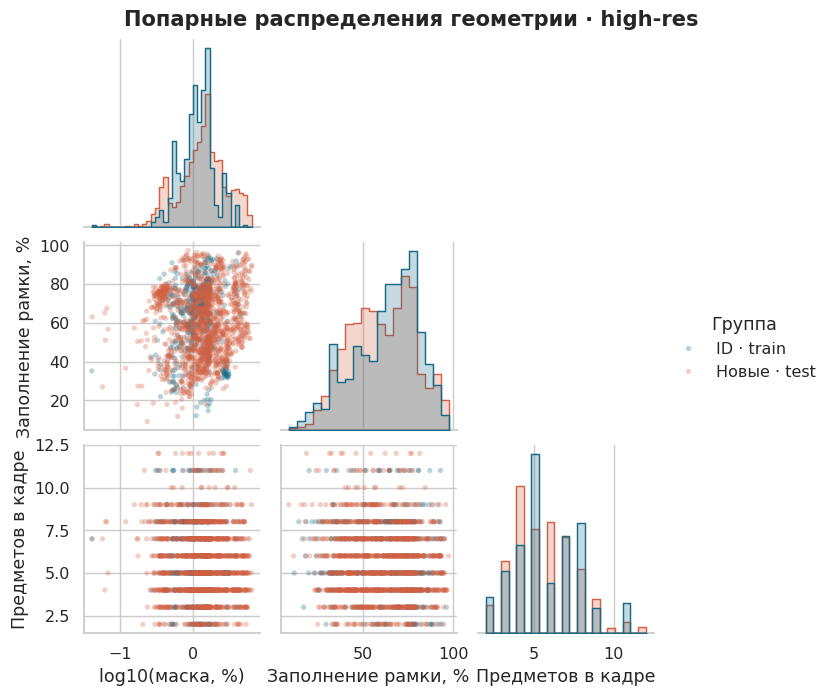

In [6]:
geometry = plot_boxes.loc[plot_boxes.camera.eq("high-res")].copy()
geometry["log10(маска, %)"] = np.log10(geometry.mask_pct)
geometry["Заполнение рамки, %"] = geometry.bbox_fill
geometry["Предметов в кадре"] = geometry.n_objects
pair = sns.pairplot(geometry, vars=["log10(маска, %)", "Заполнение рамки, %", "Предметов в кадре"],
                    hue="Группа", diag_kind="hist", corner=True,
                    plot_kws={"alpha": .30, "s": 13, "linewidth": 0},
                    diag_kws={"stat": "density", "common_norm": False, "element": "step"},
                    grid_kws={"diag_sharey": False}, height=2.15)
pair.figure.suptitle("Попарные распределения геометрии · high-res", y=1.02, fontweight="bold")
plt.show()

## 4. Ручной просмотр крайних случаев

Показываем пару сенсоров для одного примера из каждой группы, затем проверяем самые маленькую и большую маски, кадр с наибольшим числом предметов и минимумом показателя резкости. Рамки строятся по оригинальным аннотациям; оранжевым выделен выбранный экземпляр. Экстремальные случаи оставляем, если они представляют корректную сцену. Ручной просмотр примеров не заменяет полную проверку полноты разметки.

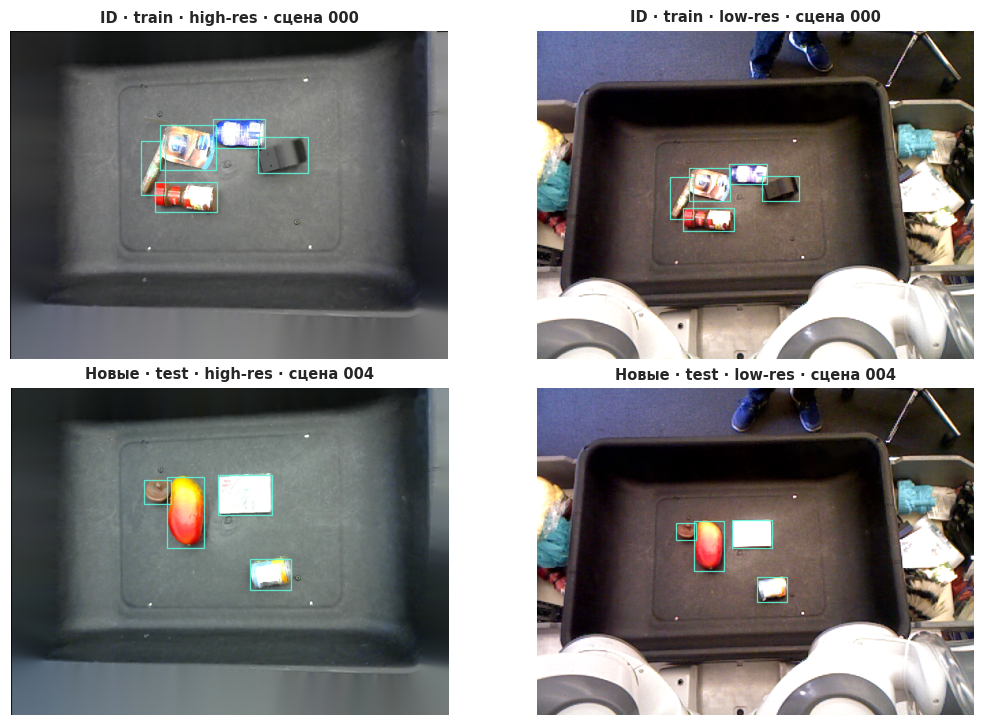

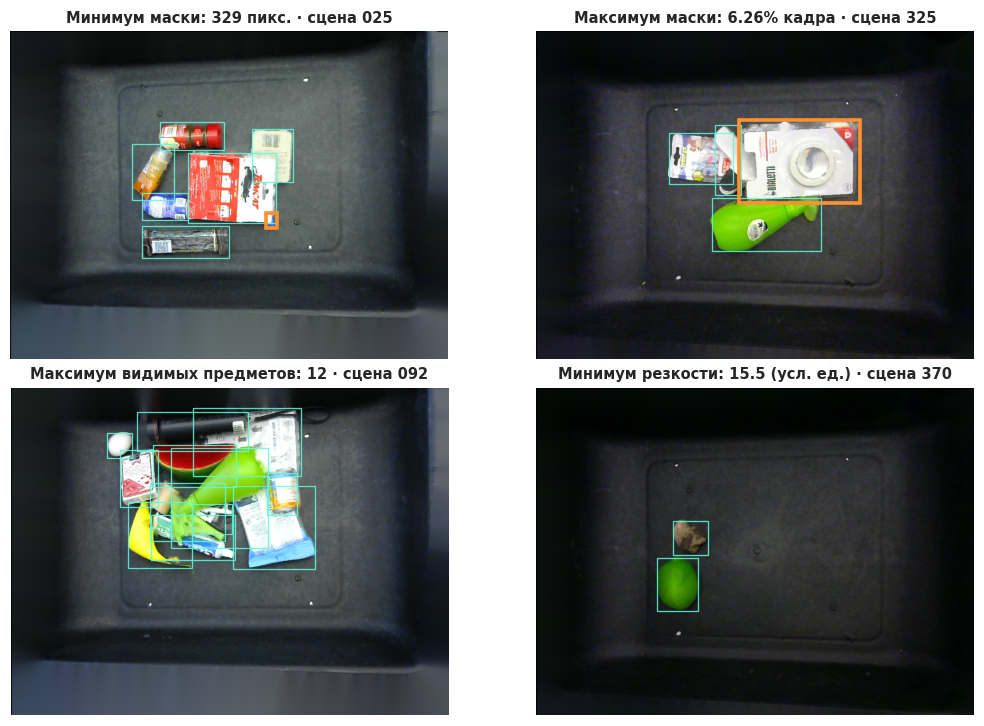

In [7]:
def show_scene(ax, camera, frame_id, title, focus=None):
    color = cv2.cvtColor(read_png(camera, "color_ims", frame_id), cv2.COLOR_BGR2RGB)
    ax.imshow(color)
    local = boxes.loc[boxes.camera.eq(camera) & boxes.frame_id.eq(frame_id)]
    for b in local.itertuples():
        selected = focus is not None and b.instance_id == focus
        ax.add_patch(Rectangle((b.x0, b.y0), b.bbox_w, b.bbox_h, fill=False,
                               edgecolor="#FF912F" if selected else "#5FFBDE",
                               lw=2.5 if selected else .9, alpha=1 if selected else .85))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig, axs = plt.subplots(2, 2, figsize=(10, 6.8), layout="constrained")
for row, split in enumerate(("train", "test")):
    frame_id = min(splits["high-res", split])
    for ax, camera in zip(axs[row], CAMERAS):
        show_scene(ax, camera, frame_id, f"{SPLIT_NAMES[split]} · {camera} · сцена {frame_id:03d}")
plt.show()

hi_boxes = boxes.loc[boxes.camera.eq("high-res")]
hi_frames = valid.loc[valid.camera.eq("high-res")]
small = hi_boxes.loc[hi_boxes.mask_pct.idxmin()]
large = hi_boxes.loc[hi_boxes.mask_pct.idxmax()]
crowded = hi_frames.loc[hi_frames.n_objects.idxmax()]
soft = hi_frames.loc[hi_frames.sharpness.idxmin()]
fig, axs = plt.subplots(2, 2, figsize=(10, 6.8), layout="constrained")
for ax, sample, label, focus in [
    (axs[0, 0], small, f"Минимум маски: {small.mask_px} пикс.", small.instance_id),
    (axs[0, 1], large, f"Максимум маски: {large.mask_pct:.2f}% кадра", large.instance_id),
    (axs[1, 0], crowded, f"Максимум видимых предметов: {int(crowded.n_objects)}", None),
    (axs[1, 1], soft, f"Минимум резкости: {soft.sharpness:.1f} (усл. ед.)", None),
]:
    show_scene(ax, "high-res", int(sample.frame_id), f"{label} · сцена {int(sample.frame_id):03d}", focus)
plt.show()

## 5. Проверка аугментаций на размеченных данных

Эксперимент только на `high-res/train`. Проверяем, как преобразования меняют вход и разметку: это проверка применимости, без заявления об улучшении качества модели. Для геометрических преобразований маска должна изменяться вместе с RGB и depth, а bounding box надо пересчитать по маске. Для дискретной маски при изменении размера используется ближайший сосед.

In [8]:
rng = np.random.default_rng(42)
aug_rows = []
aug_ids = sorted(valid.loc[valid.camera.eq("high-res") & valid.split.eq("train"), "frame_id"])
for frame_id in aug_ids:
    mask = read_png("high-res", "modal_segmasks", frame_id)
    color = read_png("high-res", "color_ims", frame_id)
    h, w = mask.shape
    before = np.bincount(mask.ravel(), minlength=256)
    instance_ids = np.flatnonzero(before[1:]) + 1

    # Проверка: отражение сохраняет площадь каждого экземпляра.
    assert np.array_equal(before, np.bincount(cv2.flip(mask, 1).ravel(), minlength=256))
    # Увеличение яркости RGB; depth и метки не меняются.
    brighter = cv2.convertScaleAbs(color, alpha=1.18, beta=0)
    # Плотность отсечения считаем только среди исходно ненасыщенных значений.
    selected = (mask > 0)[:, :, None] & (color < 255)
    new_clipping = 100 * ((brighter == 255) & selected).sum() / max(1, selected.sum())

    ch, cw = round(h * .80), round(w * .80)
    y, x = int(rng.integers(h - ch + 1)), int(rng.integers(w - cw + 1))
    crop = mask[y:y + ch, x:x + cw]
    retained = np.bincount(crop.ravel(), minlength=256)[instance_ids] / before[instance_ids]
    resized = cv2.resize(mask, (320, 240), interpolation=cv2.INTER_NEAREST)
    min_sides = [min(cv2.boundingRect(np.uint8(resized == k))[2:]) for k in instance_ids]
    aug_rows.append([frame_id, len(instance_ids), new_clipping,
                     int((retained == 0).sum()), int(((retained > 0) & (retained < .75)).sum()),
                     sum(side == 0 for side in min_sides), sum(0 < side <= 3 for side in min_sides)])

aug = pd.DataFrame(aug_rows, columns=["frame_id", "instances", "new_clipping_pct", "crop_lost",
                                     "crop_partial_lt75", "resize_lost", "resize_tiny"])
N = aug.instances.sum()
result = pd.DataFrame([
    ["Горизонтальное отражение", 0, "Площадь всех масок сохранена"],
    ["Яркость RGB × 1.18", 0, f"Медиана вновь насыщенных каналов под масками: {aug.new_clipping_pct.median():.2f}%"],
    ["Случайный crop 80% × 80%", aug.crop_lost.sum(),
     f"У {aug.crop_partial_lt75.sum()} масок сохранилось меньше 75% площади"],
    ["Resize до 320 × 240", aug.resize_lost.sum(),
     f"{aug.resize_tiny.sum()} сохранившихся рамок с короткой стороной ≤ 3 px"],
], columns=["Преобразование", "Потеряно экземпляров", "Эффект"])
result["Доля потерь, %"] = (100 * result["Потеряно экземпляров"] / N).round(2)
with pd.option_context("display.max_colwidth", None):
    display(result)
print(f"Проверено: {len(aug)} кадров, {N} видимых экземпляров.")

,Преобразование,Потеряно экземпляров,Эффект,"Доля потерь, %"
0,Горизонтальное отражение,0,Площадь всех масок сохранена,0.0
1,Яркость RGB × 1.18,0,Медиана вновь насыщенных каналов под масками: 21.31%,0.0
2,Случайный crop 80% × 80%,0,У 4 масок сохранилось меньше 75% площади,0.0
3,Resize до 320 × 240,0,0 сохранившихся рамок с короткой стороной ≤ 3 px,0.0


Проверено: 100 кадров, 491 видимых экземпляров.


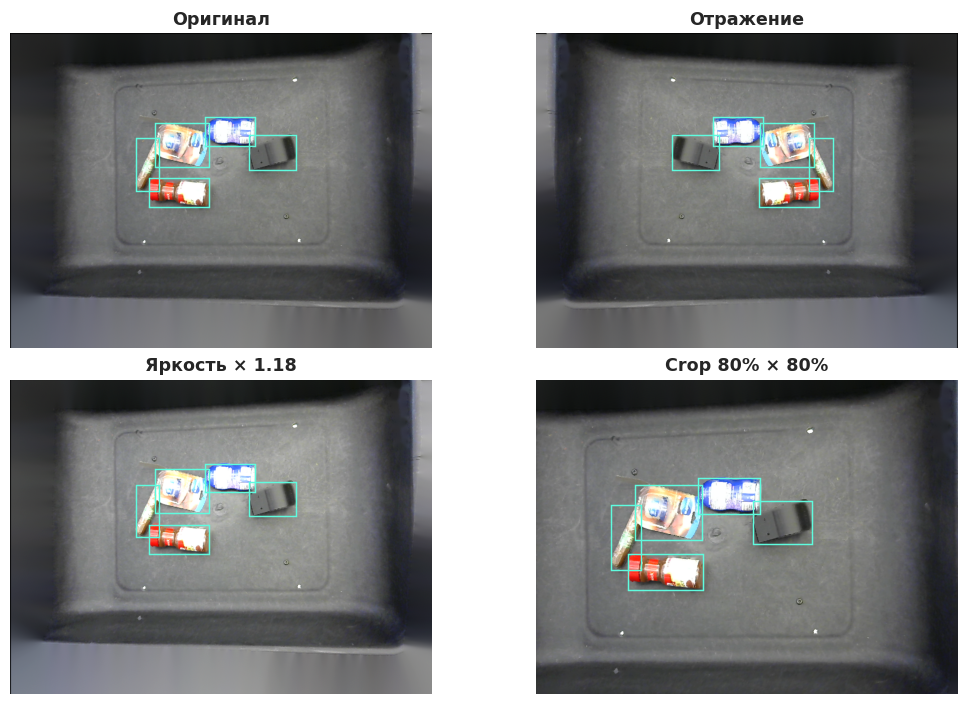

In [9]:
frame_id = aug_ids[0]
rgb = cv2.cvtColor(read_png("high-res", "color_ims", frame_id), cv2.COLOR_BGR2RGB)
mask = read_png("high-res", "modal_segmasks", frame_id)
rh, rw = mask.shape
ch, cw = round(rh * .80), round(rw * .80)
demo_rng = np.random.default_rng(42)  # для первого кадра те же координаты, что в эксперименте
y, x = int(demo_rng.integers(rh - ch + 1)), int(demo_rng.integers(rw - cw + 1))
variants = [
    ("Оригинал", rgb, mask),
    ("Отражение", cv2.flip(rgb, 1), cv2.flip(mask, 1)),
    ("Яркость × 1.18", cv2.convertScaleAbs(rgb, alpha=1.18), mask),
    ("Crop 80% × 80%", rgb[y:y+ch, x:x+cw], mask[y:y+ch, x:x+cw]),
]
fig, axs = plt.subplots(2, 2, figsize=(10, 6.6), layout="constrained")
for ax, (title, rgb_aug, mask_aug) in zip(axs.flat, variants):
    ax.imshow(rgb_aug)
    for k in np.setdiff1d(np.unique(mask_aug), [0]):
        bx, by, bw, bh = cv2.boundingRect(np.uint8(mask_aug == k))
        ax.add_patch(Rectangle((bx, by), bw, bh, fill=False, ec="#5FFBDE", lw=1))
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 6. Простой бейзлайн: локализация по фону карты глубины

Проверим, насколько далеко можно продвинуться с фиксированной камерой и без нейросети. Для кадра **high-res** подбираем 15 похожих обучающих кадров по значениям на внешней границе изображения, где обычно виден фон. Их покоординатная медиана приближает неподвижный фон. Пиксель с достаточно меньшим кодом глубины считаем кандидатом в передний план; связные компоненты дают прямоугольники. Код обработанного PNG измеряем в уровнях яркости, расстояние в метрах не восстанавливаем.

Сто сцен из официальной обучающей группы случайно делим на **70 / 15 / 15**: кадры для оценки фона, валидация для выбора порога и отложенная проверка на предметах из обучающей группы. Это разбиение по сценам, без гарантии разделения физических предметов внутри этой группы. Официальный тест с другими предметами используется только для финальной оценки. Маски проверочных кадров нужны для метрик, в алгоритм поиска они не поступают.

In [10]:
baseline_view = "high-res"
baseline_size = (344, 257)  # ширина, высота
baseline_thresholds = (2, 4, 6, 8, 10, 12)
baseline_neighbors = 15
baseline_min_area = 12  # пикселей после уменьшения
baseline_kernel = np.ones((3, 3), dtype=np.uint8)
baseline_index = images.loc[images["ok"] & images["camera"].eq(baseline_view)]
known_ids = np.sort(baseline_index.loc[baseline_index["split"].eq("train"), "frame_id"].unique())
novel_ids = np.sort(baseline_index.loc[baseline_index["split"].eq("test"), "frame_id"].unique())
assert len(known_ids) == 100 and len(novel_ids) == 300, "Неполный набор пригодных сцен для протокола 70/15/15"
shuffled = np.random.default_rng(2026).permutation(known_ids)
reference_ids, validation_ids, holdout_ids = shuffled[:70], shuffled[70:85], shuffled[85:]
baseline_gt = {
    int(frame_id): group[["x0", "y0", "x1", "y1"]].to_numpy(dtype=float)
    for frame_id, group in boxes.loc[boxes["camera"].eq(baseline_view)].groupby("frame_id")
}

def read_baseline_depth(frame_id):
    path = ROOT / baseline_view / "depth_ims" / f"image_{int(frame_id):06d}.png"
    depth = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if depth is None:
        raise ValueError(f"Не удалось прочитать {path}")
    reduced = cv2.resize(depth, baseline_size, interpolation=cv2.INTER_AREA).astype(np.float32)
    return reduced, depth.shape

baseline_refs = np.stack([read_baseline_depth(i)[0] for i in reference_ids])
# Редкая сетка по краям экономит вычисления при сравнении с опорными кадрами.
bw, bh = baseline_size
rr, cc = np.mgrid[:bh:6, :bw:6]
outer = (rr < bh * 0.1) | (rr >= bh * 0.9) | (cc < bw * 0.1) | (cc >= bw * 0.9)
border_y, border_x = rr[outer], cc[outer]
baseline_border_refs = baseline_refs[:, border_y, border_x]

def depth_residual(frame_id):
    depth, original_hw = read_baseline_depth(frame_id)
    distances = np.abs(baseline_border_refs - depth[border_y, border_x]).mean(axis=1)
    closest = np.argsort(distances, kind="stable")[:baseline_neighbors]
    background = np.median(baseline_refs[closest], axis=0)
    return background - depth, original_hw, float(distances[closest].mean())

def residual_boxes(delta, shape, threshold):
    foreground = (delta >= threshold).astype(np.uint8)
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_OPEN, baseline_kernel)
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, baseline_kernel)
    _, _, components, _ = cv2.connectedComponentsWithStats(foreground, connectivity=8)
    hw, ww = shape
    sx, sy = ww / bw, hw / bh
    return np.array([
        [int(np.floor(x * sx)), int(np.floor(y * sy)),
         min(ww, int(np.ceil((x + w) * sx))), min(hw, int(np.ceil((y + h) * sy)))]
        for x, y, w, h, area in components[1:] if area >= baseline_min_area
    ], dtype=float).reshape(-1, 4)

def count_bbox_matches(pred, true, min_iou=0.5):
    if not len(pred) or not len(true):
        return 0
    low = np.maximum(pred[:, None, :2], true[None, :, :2])
    high = np.minimum(pred[:, None, 2:], true[None, :, 2:])
    intersect = np.maximum(high - low, 0).prod(axis=2)
    union = (pred[:, 2:] - pred[:, :2]).prod(axis=1)[:, None] + (
        true[:, 2:] - true[:, :2]).prod(axis=1)[None, :] - intersect
    iou = np.divide(intersect, union, out=np.zeros_like(intersect), where=union > 0)
    # Максимальное число взаимно однозначных совпадений при фиксированном IoU.
    match = {}

    def augment(pred_id, seen):
        for true_id in np.flatnonzero(iou[pred_id] >= min_iou):
            if true_id not in seen:
                seen.add(true_id)
                if true_id not in match or augment(match[true_id], seen):
                    match[true_id] = pred_id
                    return True
        return False

    for pred_id in range(len(pred)):
        augment(pred_id, set())
    return len(match)

def localization_scores(samples, threshold):
    tp = fp = fn = 0
    border_mae = []
    for frame_id, (delta, shape, mae) in samples.items():
        pred = residual_boxes(delta, shape, threshold)
        true = baseline_gt.get(frame_id, np.empty((0, 4)))
        n = count_bbox_matches(pred, true)
        tp += n
        fp += len(pred) - n
        fn += len(true) - n
        border_mae.append(mae)
    return {
        "Кадры": len(samples), "GT": tp + fn, "TP": tp, "FP": fp, "FN": fn,
        "Precision@0.5": tp / max(1, tp + fp), "Recall@0.5": tp / max(1, tp + fn),
        "F1@0.5": 2 * tp / max(1, 2 * tp + fp + fn),
        "Медиана ошибки фона на границе": np.median(border_mae),
    }

baseline_val = {int(i): depth_residual(i) for i in validation_ids}
baseline_grid = pd.DataFrame({t: localization_scores(baseline_val, t) for t in baseline_thresholds}).T
baseline_best = int(max(baseline_thresholds, key=lambda t: (baseline_grid.loc[t, "F1@0.5"], t)))
display(baseline_grid.rename_axis("Порог").round(3))
print(f"Порог, выбранный по валидации: {baseline_best} уровней PNG.")

,Кадры,GT,TP,FP,FN,Precision@0.5,Recall@0.5,F1@0.5,Медиана ошибки фона на границе
Порог,,,,,,,,,
2,15.0,74.0,21.0,42.0,53.0,0.333,0.284,0.307,0.091
4,15.0,74.0,26.0,45.0,48.0,0.366,0.351,0.359,0.091
6,15.0,74.0,21.0,40.0,53.0,0.344,0.284,0.311,0.091
8,15.0,74.0,17.0,52.0,57.0,0.246,0.230,0.238,0.091
10,15.0,74.0,14.0,29.0,60.0,0.326,0.189,0.239,0.091
12,15.0,74.0,11.0,15.0,63.0,0.423,0.149,0.220,0.091


Порог, выбранный по валидации: 4 уровней PNG.


,Кадры,GT,TP,FP,FN,Precision@0.5,Recall@0.5,F1@0.5,Медиана ошибки фона на границе
Отложенные сцены из train,15,79,25,26,54,0.490,0.316,0.385,0.115
Официальный тест с новыми предметами,300,1434,479,752,955,0.389,0.334,0.359,0.236


Бейзлайн на новых предметах: precision 38.9%, recall 33.4%, F1 35.9% (IoU ≥ 0.5).
Диагностика на тех же предсказаниях: официальный тест по двум интервалам ID.


,Кадры,GT,Precision@0.5,Recall@0.5,F1@0.5
0–119,60.0,295.0,0.488,0.336,0.398
120–359,240.0,1139.0,0.370,0.334,0.351


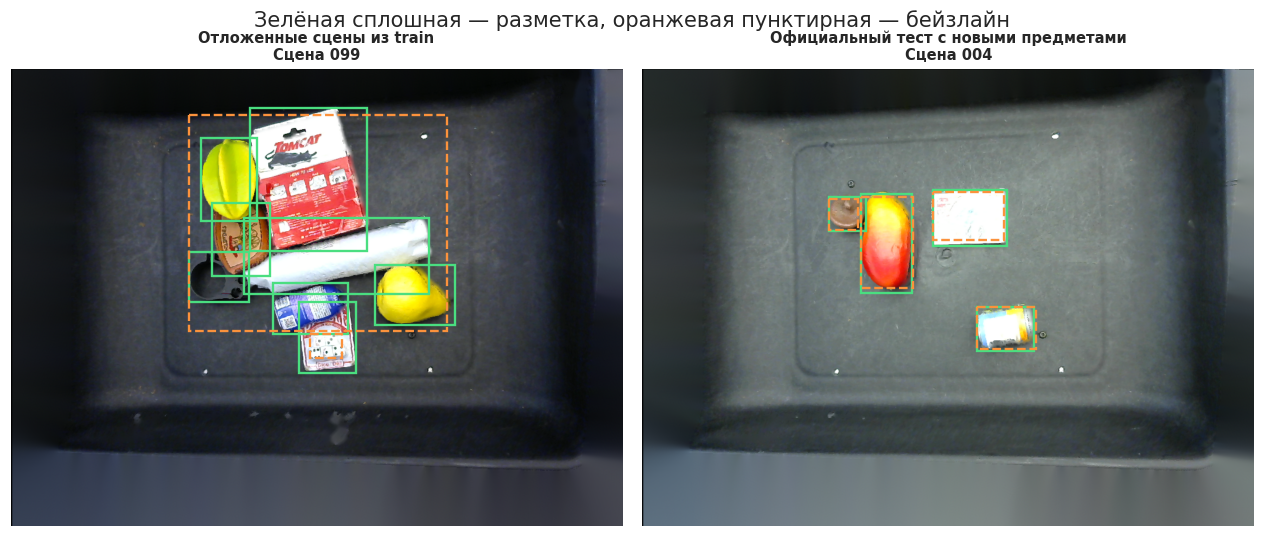

In [11]:
baseline_reports = {}
baseline_examples = []
novel_diagnostics = {}
for name, ids in (("Отложенные сцены из train", holdout_ids), ("Официальный тест с новыми предметами", novel_ids)):
    samples = {int(i): depth_residual(i) for i in ids}
    baseline_reports[name] = localization_scores(samples, baseline_best)
    if name.startswith("Официальный"):
        novel_diagnostics["0–119"] = localization_scores(
            {i: sample for i, sample in samples.items() if i < 120}, baseline_best
        )
        novel_diagnostics["120–359"] = localization_scores(
            {i: sample for i, sample in samples.items() if 120 <= i < 360}, baseline_best
        )
    example_id = int(ids[0])
    example_delta, example_shape, _ = samples[example_id]
    baseline_examples.append((name, example_id, residual_boxes(example_delta, example_shape, baseline_best)))
    del samples

baseline_table = pd.DataFrame.from_dict(baseline_reports, orient="index")
display(baseline_table.round(3))
p, r, f = baseline_table.loc["Официальный тест с новыми предметами", ["Precision@0.5", "Recall@0.5", "F1@0.5"]]
print(f"Бейзлайн на новых предметах: precision {p:.1%}, recall {r:.1%}, F1 {f:.1%} (IoU ≥ 0.5).")
print("Диагностика на тех же предсказаниях: официальный тест по двум интервалам ID.")
display(pd.DataFrame(novel_diagnostics).T[["Кадры", "GT", "Precision@0.5", "Recall@0.5", "F1@0.5"]].round(3))

from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, (name, frame_id, pred) in zip(axes, baseline_examples):
    path = ROOT / baseline_view / "color_ims" / f"image_{frame_id:06d}.png"
    ax.imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB))
    for color, style, marks in [
        ("#4ade80", "-", baseline_gt.get(frame_id, ())),
        ("#fb923c", "--", pred),
    ]:
        for x0, y0, x1, y1 in marks:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                                   fill=False, edgecolor=color, linestyle=style, linewidth=1.6))
    ax.set_title(f"{name}\nСцена {frame_id:03d}", fontsize=10)
    ax.axis("off")
fig.suptitle("Зелёная сплошная — разметка, оранжевая пунктирная — бейзлайн")
plt.show()

Эта метрика оценивает **локализацию**, а не способность отличить известный класс от неизвестного. Две группы различаются сценами и физическими предметами, а возможные различия фона и условий съёмки также могут влиять на результат. В частности, связные компоненты могут объединять соседние предметы; маленькие, перекрытые и малоконтрастные объекты могут пропадать после пороговой обработки. Ошибка совпадения фона на границе — диагностика в кодах PNG, а не метрика точности сенсора. Если меняется камера или контейнер, фон придётся оценить заново. Следующий детектор следует сравнивать на тех же кадрах и при том же пороге IoU; для вероятностной модели дополнительно считать AP по боксам.

## 7. Выводы и решения для следующего этапа

1. **Данные пригодны для проверки локализации новых предметов.** В 400 сценах проверено 800 RGB-D кадров: 100 обучающих сцен (200 кадров, 985 видимых масок) и 300 тестовых сцен с другими физическими предметами (600 кадров, 2 864 маски). Дисбаланс 1:3 по сценам задан протоколом и ничего не говорит о частоте неизвестных предметов на складе. Категориальных меток нет, поэтому неизвестность внутри смешанного кадра этот эксперимент не проверяет.
2. **Проверки не выявили битых файлов, пустых масок, недопустимых рамок или точных RGB-дубликатов.** Один кадр содержит пропуск в нумерации экземпляров, его не удаляли. В 22 из 400 пар сенсоров число видимых масок различается. Две камеры не удваивают число независимых сцен: разбиение и будущие доверительные интервалы следует строить по сценам, метрики по сенсорам — публиковать отдельно. Нет метаданных для проверки совпадения SKU внутри авторской обучающей группы.
3. **Типичный объект занимает небольшую часть кадра.** Медиана площади видимой маски на тесте — 1,39% кадра у high-res и 0,84% у low-res. На просмотренных примерах встречаются узкие видимые фрагменты, плотные укладки (до 12 видимых экземпляров) и тёмные кадры. Их сохраняем как реалистичные трудные случаи. При сравнении моделей будем отдельно смотреть результаты по размерам рамок, плотности укладки и сенсору.
4. **Разбиение связано с режимом съёмки или обработки depth.** У high-res около ID 120 средняя интенсивность depth резко меняется примерно с 149 до 134 уровней PNG. До этой границы 60 сцен ID и 60 сцен с новыми предметами; далее до ID 359 — 240 тестовых сцен и ни одной обучающей. Это видно и по второму сенсору. Мы не знаем точной причины скачка, но общий результат на тесте смешивает смену предметов со сменой условий. Следует сравнивать RGB и RGB-D и отдельно показывать метрики на ранних и поздних сценах, не подбирая параметры на официальном тесте. Средняя интенсивность PNG не подходит как признак «неизвестного предмета».
5. **Из проверенных аугментаций начнём с отражения и более мягкого изменения яркости.** Отражение сохранило площадь всех масок. Усиление яркости на 18% перевело в насыщение медианные 21,31% изначально ненасыщенных значений RGB под масками. Crop 80% × 80% не убрал ни одного экземпляра, но у четырёх из 491 маски осталось меньше 75% площади. Resize до 320 × 240 не стёр ни одну маску в этом опыте; влияние на текстуры и качество детекции надо проверять отдельно. Для геометрических преобразований используем одни и те же параметры для RGB, depth и маски.
6. **Бейзлайн находит только около трети новых экземпляров.** На 300 сценах high-res с новыми предметами: precision 38,9%, recall 33,4%, F1 35,9% при IoU ≥ 0,5. В двух интервалах теста полнота почти одинакова (33,6% и 33,4%), но точность падает с 48,8% до 37,0%; это диагностика разных групп сцен, а не доказательство причины. Бейзлайн даёт ориентир для будущего нейросетевого детектора и не оценивает распознавание новизны. Следующий эксперимент: обучить простой детектор видимых экземпляров, заморозить выбор порога на валидации и сравнить его на тех же кадрах. Для сценария «отличить новый товар от знакомого и отправить оператору» нужен следующий набор: SKU-разметка, известные и неизвестные предметы вместе, отдельные сцены для настройки порога и финальной проверки. Проверку практической пользы описывает [отдельный PDF](Практическое_значение.pdf).